# Kristiansund bridge planning


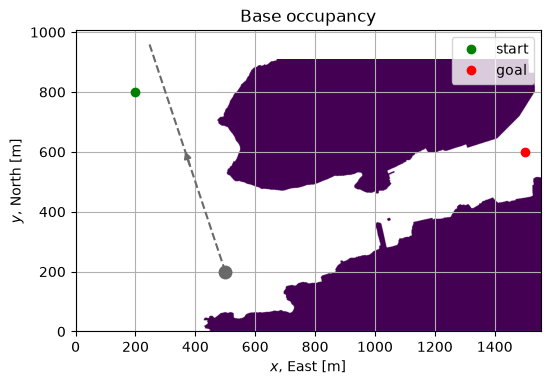

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cartoblobpy.graph import Graph

from risk_informed_planner.licenses import pysmile_license
from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *

g = Graph()
g.load_from_yaml("../maps/kristiansund_bridge/map.yaml")
# g.goal = (1850.0, 1800.0)
g.start = (200.0, 800.0)
g.goal = (1500, 600.0)
obstacles = [
    # LinearDynamicObstacle.create(start_pose=(1450.0, 600.0), end_pose=(500.0, 250.0), velocity=3.0),
    LinearDynamicObstacle.create(start_pose=(500.0, 200.0), end_pose=(300.0, 800.0), velocity=2.0),
    # LinearDynamicObstacle.create(start_pose=(500.0, 700.0), end_pose=(100.0, 100.0), velocity=1.0),
    # LinearDynamicObstacle.create(start_pose=(1500.0, 1100.0), end_pose=(250.0, 1100.0), velocity=3.0),
    # LinearDynamicObstacle.create(start_pose=(2300.0, 1800.0), end_pose=(5400.0, 4000.0), velocity=5.0),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

In [2]:
from risk_informed_planner.config import Config
from risk_informed_planner.risk import cost_model
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
)
from risk_informed_planner.utils import Node

start = Node(g.start[0], g.start[1], 0)
goal = Node(g.goal[0], g.goal[1], -1)


In [3]:
import time

max_nodes = 1200
cfg = Config(
    X_LIMITS=(0, g.width),
    Y_LIMITS=(0, g.height),
    STEP_SIZE=50,
    GOAL_RADIUS=75,
    NEIGHBOR_RADIUS=150,
    MAX_NODES=max_nodes,
    # MAX_NEIGHBORS_RISK_RENEWAL=None,
    ALPHA=0.1,
    BETA=100.0,
    GAMMA=0.6,
    MAX_TURN_ANGLE=np.pi / 4.0,
    RISK_CUTOFF=0.10,
    RISK_SAMPLE_SPACING=15.0,
    RISK_AGGREGATION="max"
)

min_depth=6.0
risk_model = DynamicRisk(
    max_distance_from_shore=150.0,
    lookahead_distance=150.0,
    graph=g,
    obstacles=obstacles,
    max_dcpa_for_collision_risk=100.0,
    max_tcpa_for_collision_risk=120.0,
    max_relative_velocity_for_collision_risk=5.0,
    max_depth_for_grounding_risk=200.0,
    grounding_depth_hard_limit=min_depth,
    desired_speed=3.0,
    cost_model=cost_model.NormalizedExpectedLoss(),

)
# cfg.RISK_CUTOFF=risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network) / 4.0

path_planner = RiskAwareAngleCostRRTStarSearch(
    start=start,
    goal=goal,
    graph=g,
    cfg=cfg,
    risk_model=risk_model,
    # callback_functions=[],
    record_bbn_snapshots=True,
    min_depth=min_depth,
    free_check_method=RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.DEPTH_SAMPLING_OCCUPANCY_CHECKS
)


In [4]:
start_time = time.perf_counter()
nodes, path = path_planner()
total_computation_time = time.perf_counter() - start_time
print(f"Planning completed in {total_computation_time:.2f} seconds.")

Progress:   0%|          | 0/1200 [00:00<?, ?node/s]

Planning completed in 23.90 seconds.


In [5]:
from risk_informed_planner.experiment import PlannerRun

# Save the run so plots can be iterated on in kristiansund_bridge_figures.ipynb without re-planning.
run_file = PlannerRun(
    nodes=nodes,
    path=path,
    cfg=cfg,
    graph=g,
    obstacles=obstacles,
    t_computation=total_computation_time,
    speed=risk_model.desired_speed,
    map_file="../maps/kristiansund_bridge/map.yaml",  # map is re-read from here on load
    metadata=dict(
        cost_model=type(risk_model.cost_model).__name__,
        planner=type(path_planner).__name__,
    ),
).save("results/study_03.pkl")
print(f"saved to {run_file}")

saved to results/study_03.pkl


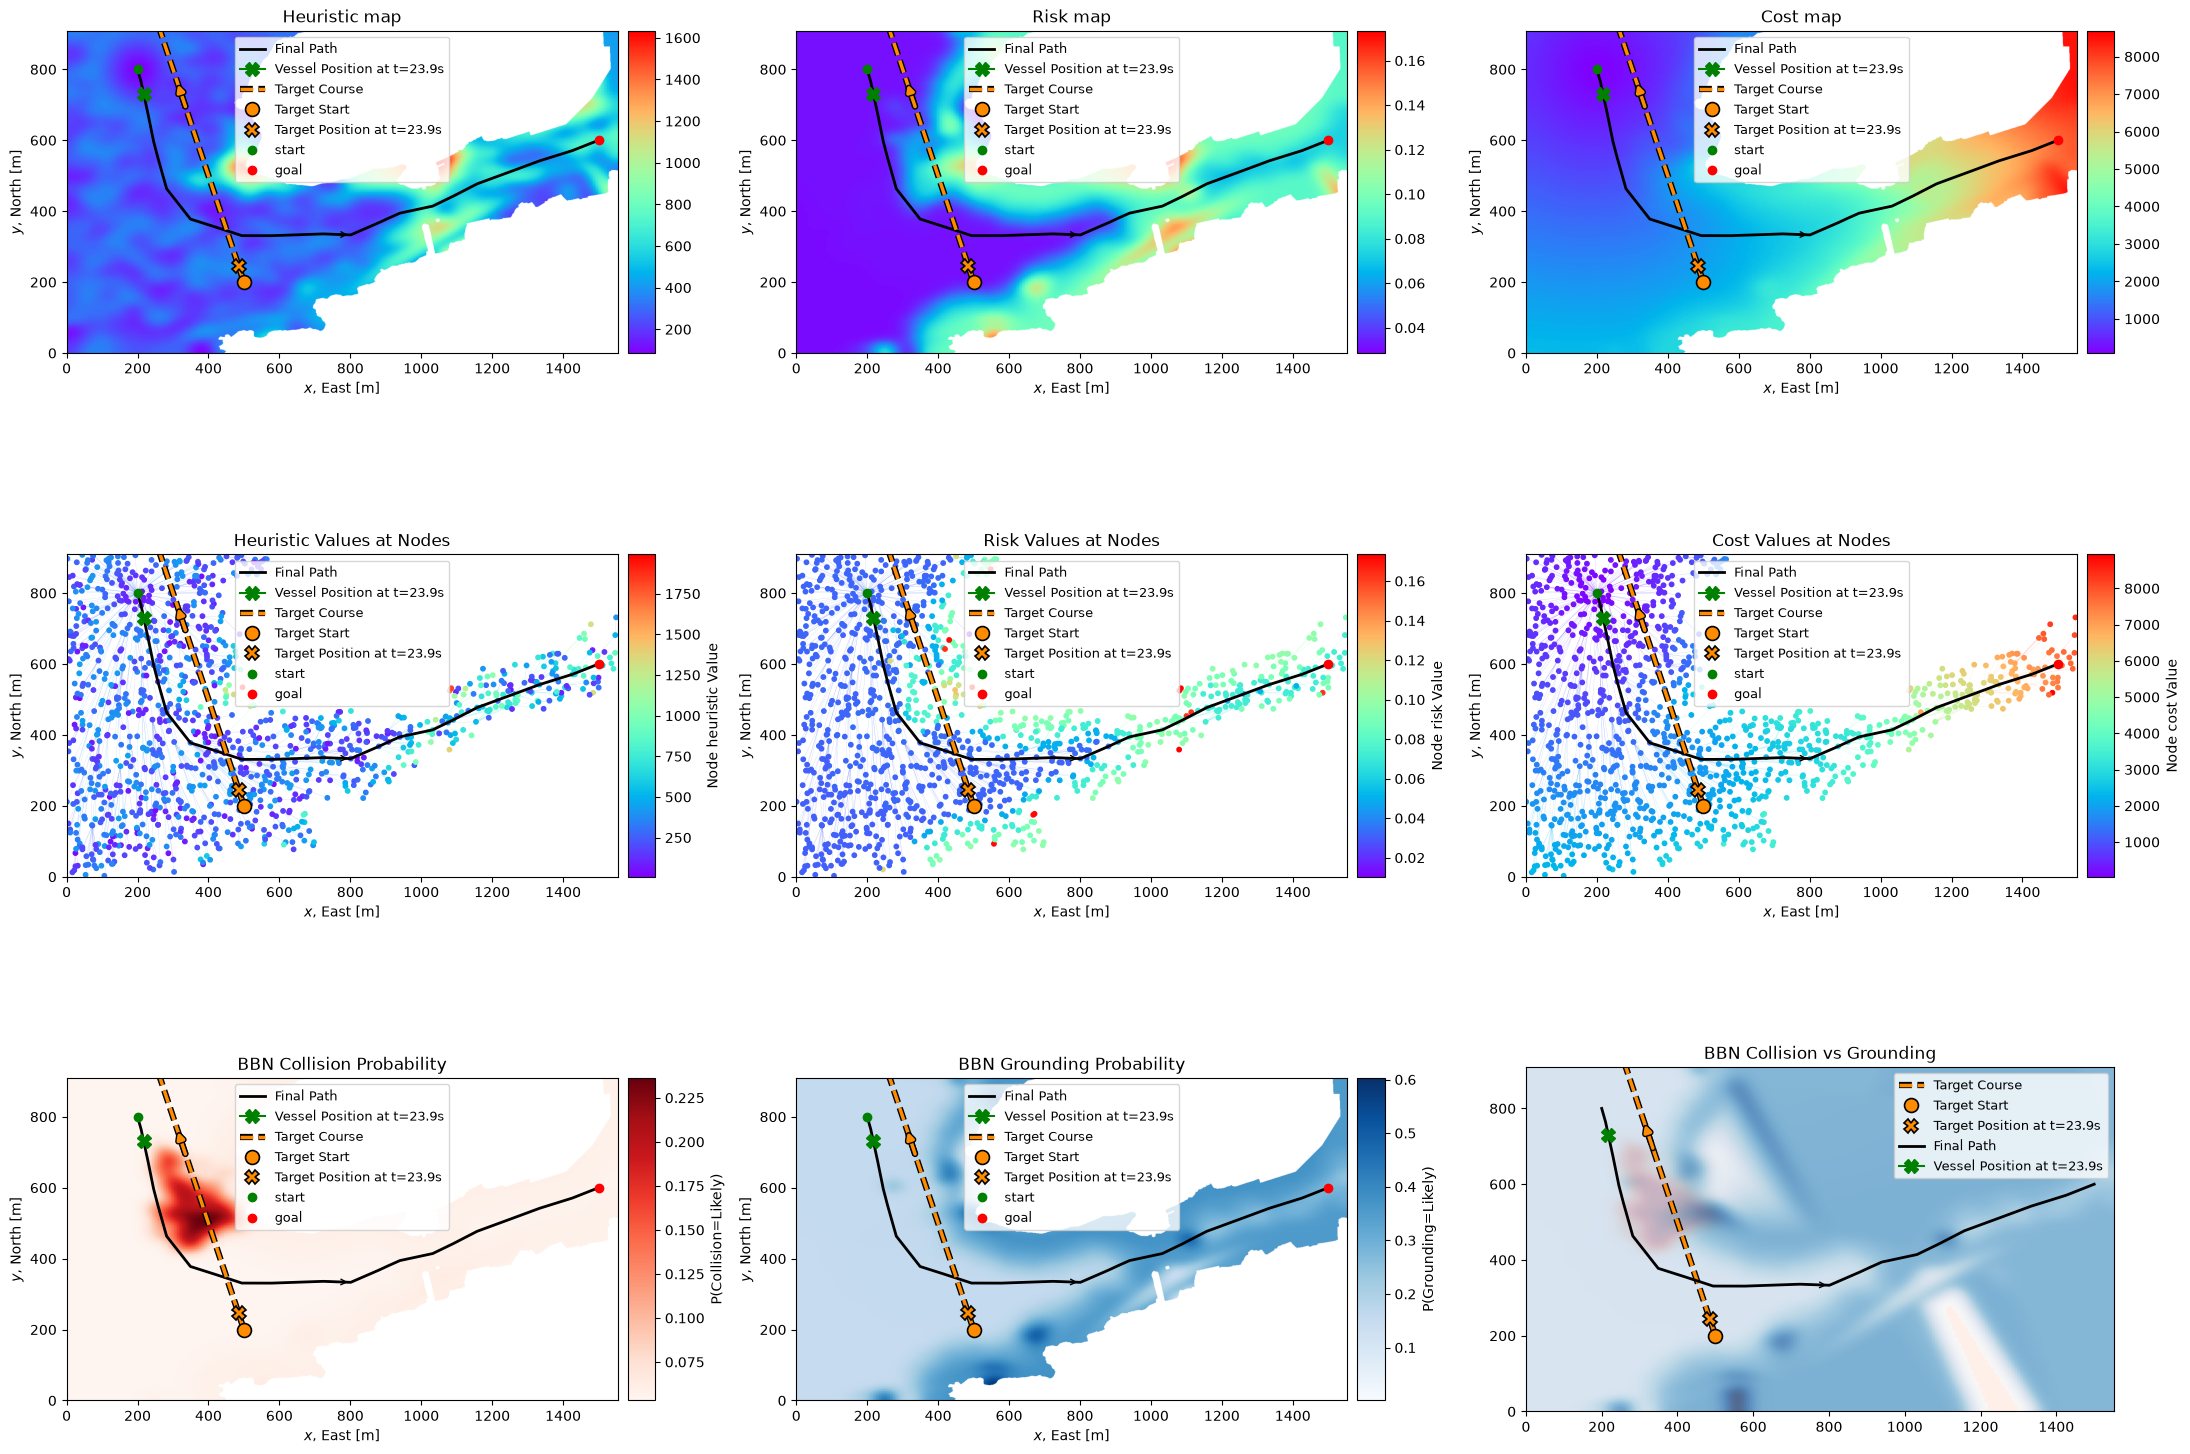

In [6]:
from risk_informed_planner.visualization import *

fig, ax = plt.subplots(3, 3, figsize=(22, 16))

axes = plot_matrix(
    nodes=nodes,
    obstacles=obstacles,
    path=path,
    cfg=cfg,
    graph=g,
    ax=ax,
    t_computation=total_computation_time,
    speed=risk_model.desired_speed
)
plt.savefig(f"plots/kristiansund_bridge_{type(risk_model.cost_model).__name__}_alpha_{cfg.ALPHA}_beta_{cfg.BETA}.pdf")

A {'P(Collision)': 0.215, 'P(Grounding)': 0.198}
B {'P(Collision)': 0.058, 'P(Grounding)': 0.375}


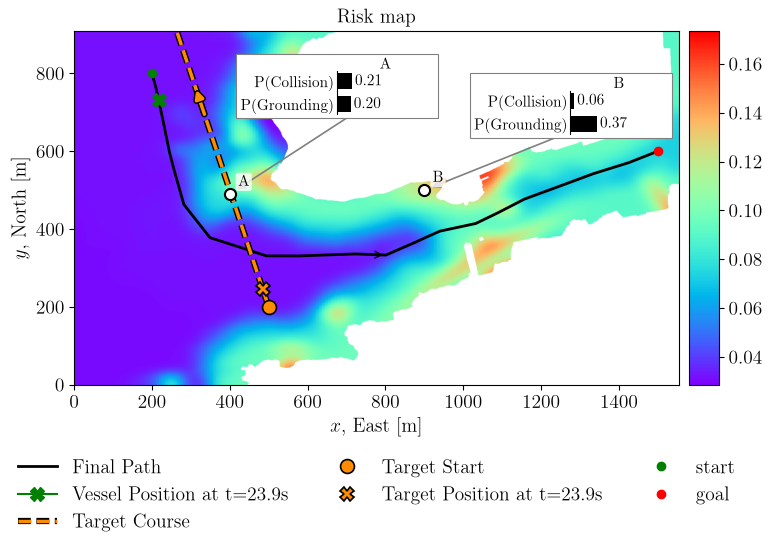

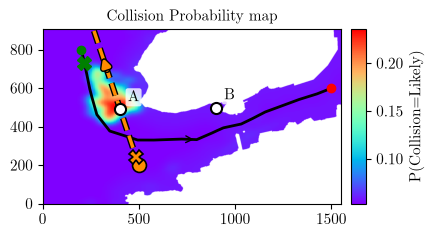

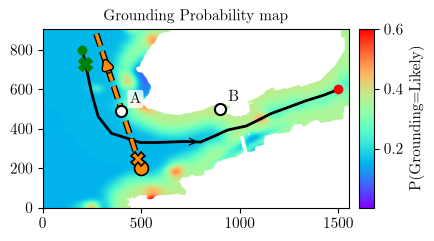

In [8]:
from risk_informed_planner.visualization import *

# Paper layout: one large risk heatmap, two small hazard heatmaps stacked on its side.
# Plotting and annotating live in one cell, so each run redraws clean figures and
# shows the bar charts right away.
save_prefix = f"kristiansund_bridge_{type(risk_model.cost_model).__name__}_alpha_{cfg.ALPHA}_beta_{cfg.BETA}_"

panels = plot_paper_panels(
    nodes=nodes,
    path=path,
    cfg=cfg,
    graph=g,
    obstacles=obstacles,
    t_computation=total_computation_time,
    speed=risk_model.desired_speed,
    latex=True,  # set to True for LaTeX-rendered text (slower to compile)
    modes=("heatmap",),
    # per-metric color-scale bounds; None = fit to that panel's own data range
    vmin={"risk": None, "collision": None, "grounding": None},
    vmax={"risk": None, "collision": None, "grounding": None},
    figsize={"risk": (8, 7), "collision": (4.5, 4), "grounding": (4.5, 4)},
    fontsize={"risk": 14, "collision": 11, "grounding": 11},
    legend={"collision": False, "grounding": False},
    axis_labels={"collision": False, "grounding": False},
    legend_rows=3,
)

# Explain points of the risk map: C / G bars are the collision / grounding probability
# read from the same pixel of the hazard heatmaps. All coordinates are map units.
# xy: point of interest, inset_xy: center of the bar chart (arrow runs between them).
drivers = annotate_hazard_drivers(
    panels,
    points=[
        dict(xy=(400.0, 490.0), inset_xy=(800.0, 750.0), label="A"),
        dict(xy=(900.0, 500.0), inset_xy=(1400.0, 700.0), label="B"),
    ],
    fontsize=11,
)
for d in drivers:
    print(d["label"], {k: round(v, 3) for k, v in d["values"].items()})

save_paper_panels(panels, save_dir="plots", save_prefix=save_prefix)